# Statistic Analysis of UEs

This notebook visualizes metrics for UEs, including:

- Average throughput per UE

- Q queues stability (RLC queues)

- G queues stability (virtual queues)

- Allocated Resource Blocks (RBs)

The data comes from the ue_qos_stats.csv file generated by the gNB MAC scheduler.

## Imports

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

## Load data from file

In [3]:
# Load the CSV file
file_path = '~/MAC_sched_OAI/openairinterface5g/cmake_targets/ran_build/build/ue_qos_stats.csv'
df = pd.read_csv(file_path)

# Verify that the required columns exist
if 'UID' not in df.columns or 'Current_throughput' not in df.columns:
    raise ValueError("The CSV must contain the columns 'UID' and 'Current_throughput'.")

# Show information about the DataFrame
print(len(df))
print(f"Columns: {list(df.columns)}")
print(f"\nFirst rows:")
df.head(10)

154236
Columns: ['Time', 'Frame', 'Slot', 'RNTI', 'UID', 'LCID', 'Q', 'G', 'Current_throughput', 'RBs', 'GFBR', 'MCS']

First rows:


,Time,Frame,Slot,RNTI,UID,LCID,Q,G,Current_throughput,RBs,GFBR,MCS
0,1770293440,236,5,28045,1,1,0,159000000,7.05,5.58,3.0,20
1,1770293440,236,5,28045,1,2,0,159000000,7.05,5.58,3.0,20
2,1770293440,236,5,28045,1,4,50061967,159000000,7.05,5.58,3.0,20
3,1770293440,236,5,27884,2,1,0,24000000,18.84,12.70,6.0,22
4,1770293440,236,5,27884,2,2,0,24000000,18.84,12.70,6.0,22
5,1770293440,236,5,27884,2,4,25554319,24000000,18.84,12.70,6.0,22
6,1770293440,236,5,62887,0,1,0,33072000,9.44,6.65,3.0,18
7,1770293440,236,5,62887,0,2,0,33072000,9.44,6.65,3.0,18
8,1770293440,236,5,62887,0,4,39222317,33072000,9.44,6.65,3.0,18
9,1770293440,236,5,44902,3,1,0,49376000,14.40,11.74,6.0,18


## MCS

UE 1: Mean MCS = 20.17
UE 2: Mean MCS = 19.37
UE 3: Mean MCS = 21.07
UE 4: Mean MCS = 16.55


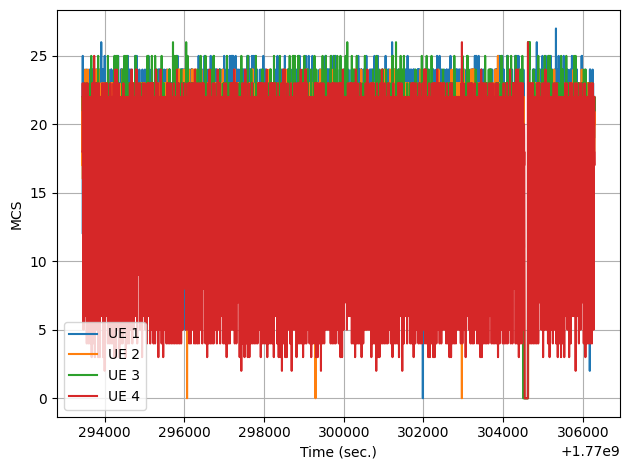

In [22]:
df = pd.read_csv(file_path)
for uid, group in df.groupby('UID'):
    # Group by unique timestamp to get one MCS per second
    unique_times = group.groupby('Time').agg({
        'MCS': 'mean'  # Average MCS if there are multiple LCIDs in the same second
    }).reset_index()
    if len(unique_times) > 0:
        # Get the end time (most recent)
        end_time = unique_times['Time'].iloc[-1]
        # Calculate the mean MCS in that window
        mean_mcs = unique_times['MCS'].mean()
        print(f"UE {uid+1}: Mean MCS = {mean_mcs:.2f}")
        # Plot the filtered data
        plt.plot(unique_times['Time'], unique_times['MCS'], label=f'UE {uid+1}')
# Etiquetas y configuración
plt.xlabel('Time (sec.)')
plt.ylabel('MCS')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Average throughput per UE

UE 1: GFBR = 3.0 Mbps
UE 1: Average throughput = 11.64 Mbps
UE 2: GFBR = 3.0 Mbps
UE 2: Average throughput = 10.11 Mbps
UE 3: GFBR = 6.0 Mbps
UE 3: Average throughput = 19.74 Mbps
UE 4: GFBR = 6.0 Mbps
UE 4: Average throughput = 12.48 Mbps


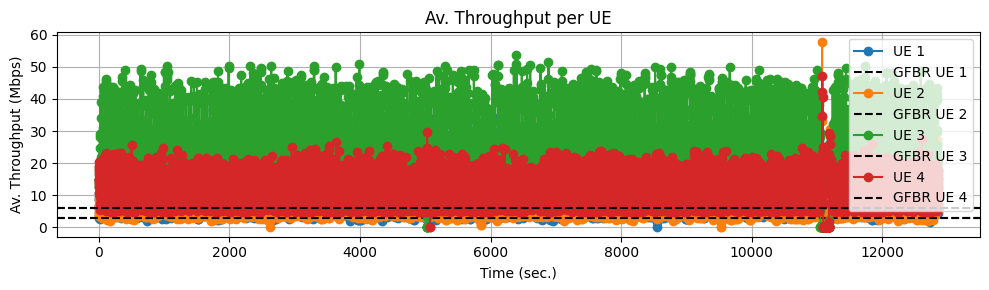

In [ ]:
import numpy as np
plt.figure(figsize=(10, 3))
df = pd.read_csv(file_path)
for uid, group in df.groupby('UID'):
    unique_times = group.groupby('Time').agg({
        'Current_throughput': 'first',
        'Q': 'sum',
        'GFBR': 'first'
    }).reset_index()
    x = range(len(unique_times))
    plt.plot(x, unique_times['Current_throughput'], marker='o', label=f'UE {uid+1}')
    # Plot the GFBR as a horizontal line
    plt.axhline(y=unique_times['GFBR'].iloc[0], color='k', linestyle='--', label=f'GFBR UE {uid+1}')
    print(f"UE {uid+1}: GFBR = {unique_times['GFBR'].iloc[0]} Mbps")
    # Calculate the average throughput
    avg_throughput = unique_times['Current_throughput'].mean()
    print(f"UE {uid+1}: Average throughput = {avg_throughput:.2f} Mbps")
plt.xlabel('Time (sec.)')
plt.ylabel('Av. Throughput (Mbps)')
plt.title('Av. Throughput per UE')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

/tmp/ipykernel_245297/1631159525.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=labels)


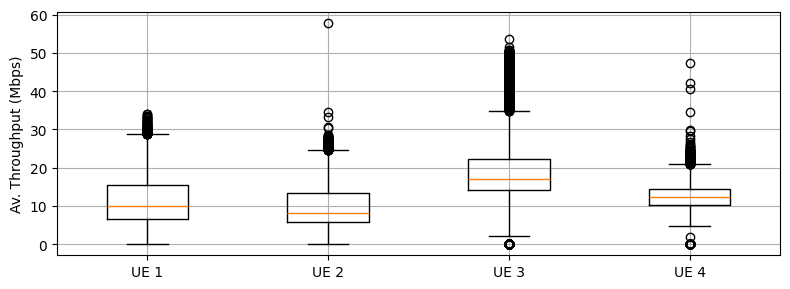

In [ ]:
df = pd.read_csv(file_path)
plt.figure(figsize=(8, 3))
data_to_plot = []
labels = []
for uid, group in df.groupby('UID'):
    unique_times = group.groupby('Time').agg({
        'Current_throughput': 'first'
    }).reset_index()
    data_to_plot.append(unique_times['Current_throughput'])
    labels.append(f'UE {uid+1}')
plt.boxplot(data_to_plot, labels=labels)
plt.ylabel('Av. Throughput (Mbps)')
plt.grid(True)
plt.tight_layout()
plt.show()

## G stability

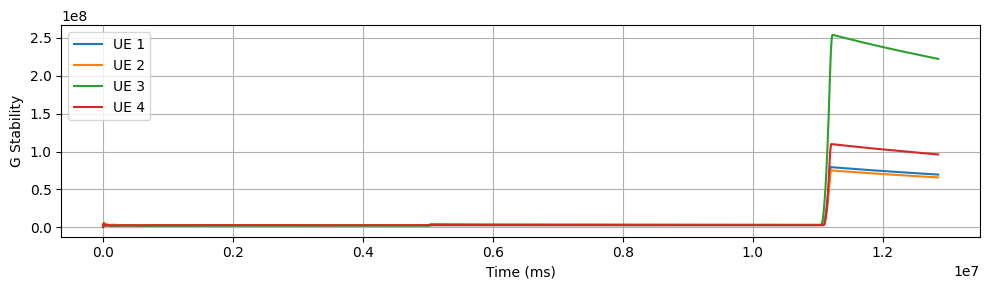

In [26]:
plt.figure(figsize=(10, 3))
df = pd.read_csv(file_path)
for uid, group in df.groupby('UID'):
    unique_times = group.groupby('Time').agg({
        'G': 'sum',
        'Current_throughput': 'first'
    }).reset_index()
    if len(unique_times) > 0:
        start_time = unique_times['Time'].iloc[0]
        unique_times['Time_ms'] = ((unique_times['Time'] - start_time) + 2) * 1000
        unique_times['Cumulative_bits'] = (unique_times['G'] * 8).cumsum()
        unique_times['Stability'] = unique_times['Cumulative_bits'] / unique_times['Time_ms']
        plt.plot(unique_times['Time_ms'], unique_times['Stability'], label=f'UE {uid+1}')
plt.xlabel('Time (ms)')
plt.ylabel('G Stability')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Q stability

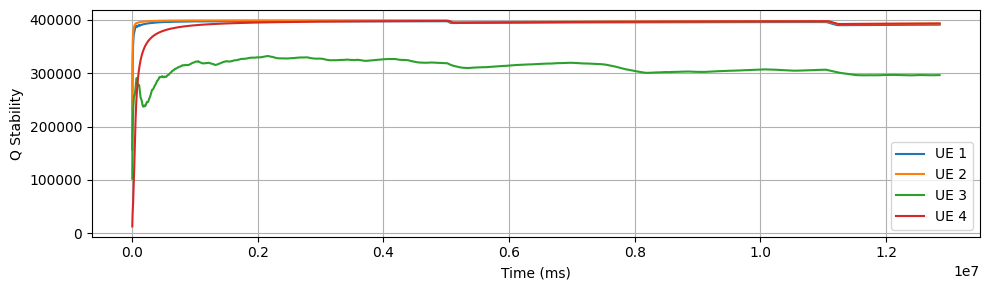

In [27]:
plt.figure(figsize=(10, 3))
df = pd.read_csv(file_path)
for uid, group in df.groupby('UID'):
    unique_times = group.groupby('Time').agg({
        'Q': 'sum',
        'Current_throughput': 'first'
    }).reset_index()
    if len(unique_times) > 0:
        start_time = unique_times['Time'].iloc[0]
        unique_times['Time_ms'] = ((unique_times['Time'] - start_time) + 2) * 1000
        unique_times['Cumulative_bits'] = (unique_times['Q'] * 8).cumsum()
        unique_times['Stability'] = unique_times['Cumulative_bits'] / unique_times['Time_ms']
        plt.plot(unique_times['Time_ms'], unique_times['Stability'], label=f'UE {uid+1}')
plt.xlabel('Time (ms)')
plt.ylabel('Q Stability')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## RBs

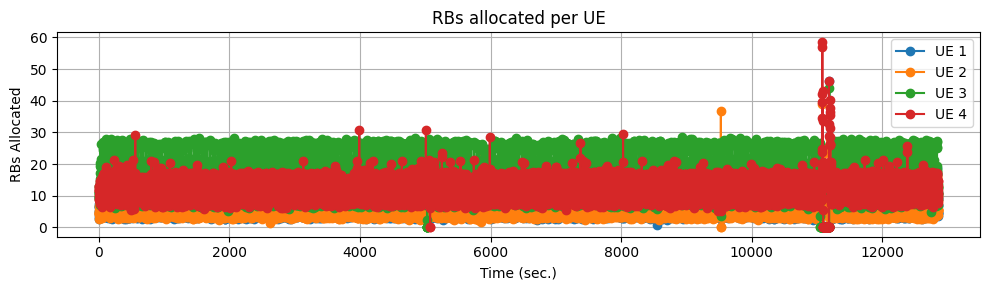

In [28]:
plt.figure(figsize=(10, 3))
df = pd.read_csv(file_path)
for uid, group in df.groupby('UID'):
    unique_times = group.groupby('Time').agg({
        'RBs': 'first',
    }).reset_index()
    x = range(len(unique_times))
    plt.plot(x, unique_times['RBs'], marker='o', label=f'UE {uid+1}')
plt.xlabel('Time (sec.)')
plt.ylabel('RBs Allocated')
plt.title('RBs allocated per UE')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

/tmp/ipykernel_245297/3035051299.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=labels)


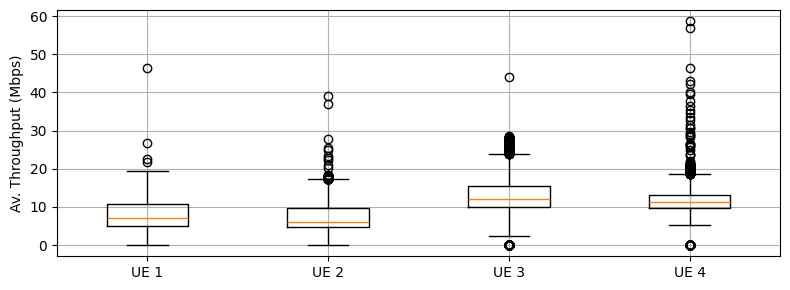

In [30]:
df = pd.read_csv(file_path)
plt.figure(figsize=(8, 3))
data_to_plot = []
labels = []
for uid, group in df.groupby('UID'):
    unique_times = group.groupby('Time').agg({
        'RBs': 'first'
    }).reset_index()
    data_to_plot.append(unique_times['RBs'])
    labels.append(f'UE {uid+1}')
plt.boxplot(data_to_plot, labels=labels)
plt.ylabel('Av. Throughput (Mbps)')
plt.grid(True)
plt.tight_layout()
plt.show()